Unweighted BMI Mean: 29.8305, 95% CI: (29.6424, 30.0187)
Weighted BMI Mean: 29.6831, 95% CI: (29.4962, 29.8700)
Bootstrap BMI Mean CI: (29.6596, 30.0236)

T-Test (Inactive vs Active BMI): t=8.9182, p-value=1.2290e-18
Effect Size (Cohen's d): 0.3137

ANOVA (Sleep Categories on BMI): F=13.4423, p-value=1.4977e-06


C:\Users\Radmehr\AppData\Local\Temp\ipykernel_10252\1689125766.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Activity_Status', y='BMXBMI', data=df, ax=axes[0], palette='Set2')
C:\Users\Radmehr\AppData\Local\Temp\ipykernel_10252\1689125766.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Sleep_Category', y='BMXBMI', data=df, ax=axes[1], palette='Set3', order=['Short', 'Adequate', 'Long'])


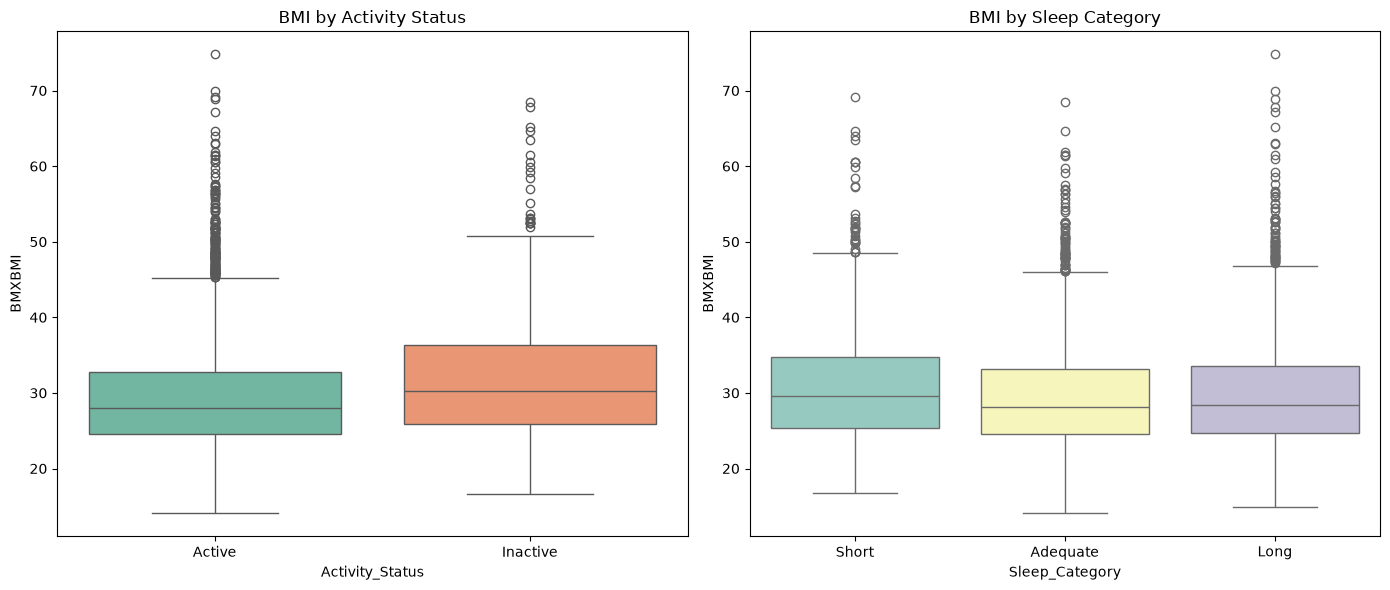

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

demo = pd.read_sas('../data/DEMO_L.xpt')
bmx = pd.read_sas('../data/BMX_L.xpt')
slq = pd.read_sas('../data/SLQ_L.xpt')
paq = pd.read_sas('../data/PAQ_L.xpt')

df = pd.merge(demo, bmx, on='SEQN', how='inner')
df = pd.merge(df, slq, on='SEQN', how='inner')
df = pd.merge(df, paq, on='SEQN', how='inner')

df = df[df['RIDAGEYR'] >= 20]
cols = ['SEQN', 'RIDAGEYR', 'RIAGENDR', 'WTINT2YR', 'WTMEC2YR', 'BMXBMI', 'SLD013', 'PAD790Q', 'PAD790U', 'PAD810Q', 'PAD810U']
df = df[cols]
df = df[~df['SLD013'].isin([77, 99])]
df = df[~df['PAD790Q'].isin([7777, 9999])]
df = df[~df['PAD810Q'].isin([7777, 9999])]
df = df.dropna()

df['PAD790Q'] = df['PAD790Q'].apply(lambda x: 0.0 if x < 1e-10 else x)
df['PAD810Q'] = df['PAD810Q'].apply(lambda x: 0.0 if x < 1e-10 else x)

def calc_weekly(row, q_col, u_col):
    val, unit = row[q_col], row[u_col]
    if val == 0: return 0
    u = str(unit).replace("b'", "").replace("'", "").upper()
    if u in ['1', '1.0', 'D']: return val * 7
    if u in ['2', '2.0', 'W']: return val
    if u in ['3', '3.0', 'M']: return val / 4.33
    if u in ['4', '4.0', 'Y']: return val / 52.0
    return 0

df['ModAct_PerWeek'] = df.apply(calc_weekly, args=('PAD790Q', 'PAD790U'), axis=1)

df['Activity_Status'] = np.where(df['ModAct_PerWeek'] > 0, 'Active', 'Inactive')
df['Sleep_Category'] = pd.cut(
    df['SLD013'], 
    bins=[0, 6.9, 8.9, 24], 
    labels=['Short', 'Adequate', 'Long']
)

mean_bmi = df['BMXBMI'].mean()
std_bmi = df['BMXBMI'].std(ddof=1)
n = len(df)
se_bmi = std_bmi / np.sqrt(n)
ci_bmi = stats.t.interval(0.95, df=n-1, loc=mean_bmi, scale=se_bmi)

w = df['WTMEC2YR']
weighted_mean_bmi = np.average(df['BMXBMI'], weights=w)
weighted_var_bmi = np.average((df['BMXBMI'] - weighted_mean_bmi)**2, weights=w)
weighted_se_bmi = np.sqrt(weighted_var_bmi / n)
weighted_ci_bmi = (weighted_mean_bmi - 1.96 * weighted_se_bmi, weighted_mean_bmi + 1.96 * weighted_se_bmi)

np.random.seed(42)
boot_means = [np.random.choice(df['BMXBMI'], size=n, replace=True).mean() for _ in range(1000)]
boot_ci = np.percentile(boot_means, [2.5, 97.5])

print(f"Unweighted BMI Mean: {mean_bmi:.4f}, 95% CI: ({ci_bmi[0]:.4f}, {ci_bmi[1]:.4f})")
print(f"Weighted BMI Mean: {weighted_mean_bmi:.4f}, 95% CI: ({weighted_ci_bmi[0]:.4f}, {weighted_ci_bmi[1]:.4f})")
print(f"Bootstrap BMI Mean CI: ({boot_ci[0]:.4f}, {boot_ci[1]:.4f})\n")

active_bmi = df[df['Activity_Status'] == 'Active']['BMXBMI']
inactive_bmi = df[df['Activity_Status'] == 'Inactive']['BMXBMI']
t_stat, p_val_t = stats.ttest_ind(inactive_bmi, active_bmi, equal_var=False)

nx, ny = len(inactive_bmi), len(active_bmi)
vx, vy = inactive_bmi.var(ddof=1), active_bmi.var(ddof=1)
sd_pooled = np.sqrt(((nx-1)*vx + (ny-1)*vy) / (nx+ny-2))
cohens_d = (inactive_bmi.mean() - active_bmi.mean()) / sd_pooled

print(f"T-Test (Inactive vs Active BMI): t={t_stat:.4f}, p-value={p_val_t:.4e}")
print(f"Effect Size (Cohen's d): {cohens_d:.4f}\n")

short_sleep = df[df['Sleep_Category'] == 'Short']['BMXBMI'].dropna()
adequate_sleep = df[df['Sleep_Category'] == 'Adequate']['BMXBMI'].dropna()
long_sleep = df[df['Sleep_Category'] == 'Long']['BMXBMI'].dropna()

f_stat, p_val_f = stats.f_oneway(short_sleep, adequate_sleep, long_sleep)
print(f"ANOVA (Sleep Categories on BMI): F={f_stat:.4f}, p-value={p_val_f:.4e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(x='Activity_Status', y='BMXBMI', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('BMI by Activity Status')

sns.boxplot(x='Sleep_Category', y='BMXBMI', data=df, ax=axes[1], palette='Set3', order=['Short', 'Adequate', 'Long'])
axes[1].set_title('BMI by Sleep Category')

plt.tight_layout()
plt.savefig('../figures/phase3_inference.png')
plt.show()